## Parcial práctico T2 - Red social con grafos, BFS y DFS

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Giovanni Alejandro Castillo Buitrago" # @param {"type":"string"}
carnet = 1000115755 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

En este parcial hay que armar una red social con grafos. Cada usuario es un vértice y cada amistad es una arista. Las amistades van en los dos sentidos, entonces el grafo es no dirigido. La red del comienzo tiene 7 usuarios (Ana, Carlos, Laura, Mateo, Sofía, Daniel y Valentina) y 7 amistades.

Lo que se pide es guardar la red con una lista de adyacencia, recorrerla con BFS (con una cola) y con DFS (recursivo), dejar que el usuario escoja desde quién empezar, buscar la ruta con menos conexiones entre dos personas usando BFS y agregar un usuario nuevo conectado con mínimo dos usuarios que ya existan. No se pueden usar librerías que ya tengan BFS o DFS y no se pueden repetir las amistades.

BFS sirve para los grados de separación porque primero visita a los amigos directos, después a los amigos de los amigos y así. Entonces la primera vez que llega a una persona lo hace por el camino más corto.


## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.


**Funcionales**

- RF1. Guardar los usuarios y las amistades en una lista de adyacencia, con cada amistad en los dos sentidos.
- RF2. Mostrar cada usuario con sus amigos directos.
- RF3. Hacer BFS desde un usuario y mostrar el orden de visita y el grado de separación.
- RF4. Hacer DFS desde un usuario y mostrar el orden de visita.
- RF5. Pedir el usuario inicial y hacer BFS y DFS desde él. Si no existe, mostrar un mensaje de error.
- RF6. Pedir un usuario inicial y uno destino y mostrar la ruta con menos conexiones y los grados de separación. Si no hay conexión, avisarlo.
- RF7. Agregar un usuario nuevo conectado con mínimo dos usuarios existentes y mostrar la red actualizada.
- RF8. No guardar dos veces la misma amistad.

**No funcionales**

- RNF1. Usar lista de adyacencia.
- RNF2. BFS con cola y DFS con recursividad.
- RNF3. Cada usuario se visita una sola vez en cada recorrido (con una estructura de visitados).
- RNF4. No usar librerías que ya hagan BFS o DFS.
- RNF5. Los mensajes de error tienen que ser claros.
- RNF6. El código tiene que ser fácil de leer, con funciones pequeñas, y debe correr en Python 3.


## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.

**HU1. Ver la red**
Como usuario quiero ver cada persona con sus amigos, para saber cómo está armada la red.
- Criterios de aceptación:
  - Se muestra una línea por usuario, por ejemplo `Ana: Carlos, Laura`.
  - Si Ana es amiga de Carlos, Carlos también tiene a Ana en su lista.

**HU2. Explorar desde cualquier usuario**
Como analista quiero escoger desde qué usuario hago BFS y DFS, para ver cómo se va expandiendo la red.
- Criterios de aceptación:
  - BFS muestra el orden de visita y los usuarios por grado de separación.
  - DFS muestra el orden de visita.
  - Ningún usuario se repite en un recorrido.
  - Si el nombre no existe sale un mensaje de error.

**HU3. Buscar la ruta más corta**
Como usuario quiero saber la ruta más corta entre dos personas, para ver por quién me pueden presentar.
- Criterios de aceptación:
  - Se muestra la ruta, por ejemplo `Ana -> Carlos -> Sofía -> Valentina`, y los grados de separación.
  - Si no hay conexión entre los dos, se avisa.

**HU4. Agregar un usuario**
Como administrador quiero agregar un usuario nuevo con sus conexiones, para que la red vaya creciendo.
- Criterios de aceptación:
  - El usuario nuevo se conecta con mínimo dos usuarios que ya existen.
  - Después de agregarlo se muestra la red actualizada.
  - BFS, DFS y la ruta funcionan con el usuario nuevo.

**HU5. No repetir datos**
Como administrador quiero que no se repitan usuarios ni amistades, para que los datos estén bien.
- Criterios de aceptación:
  - Si la amistad ya existe, no se vuelve a guardar.
  - No se puede crear un usuario con un nombre que ya existe.


## 4) Diagramas de flujo **[5 pts]**
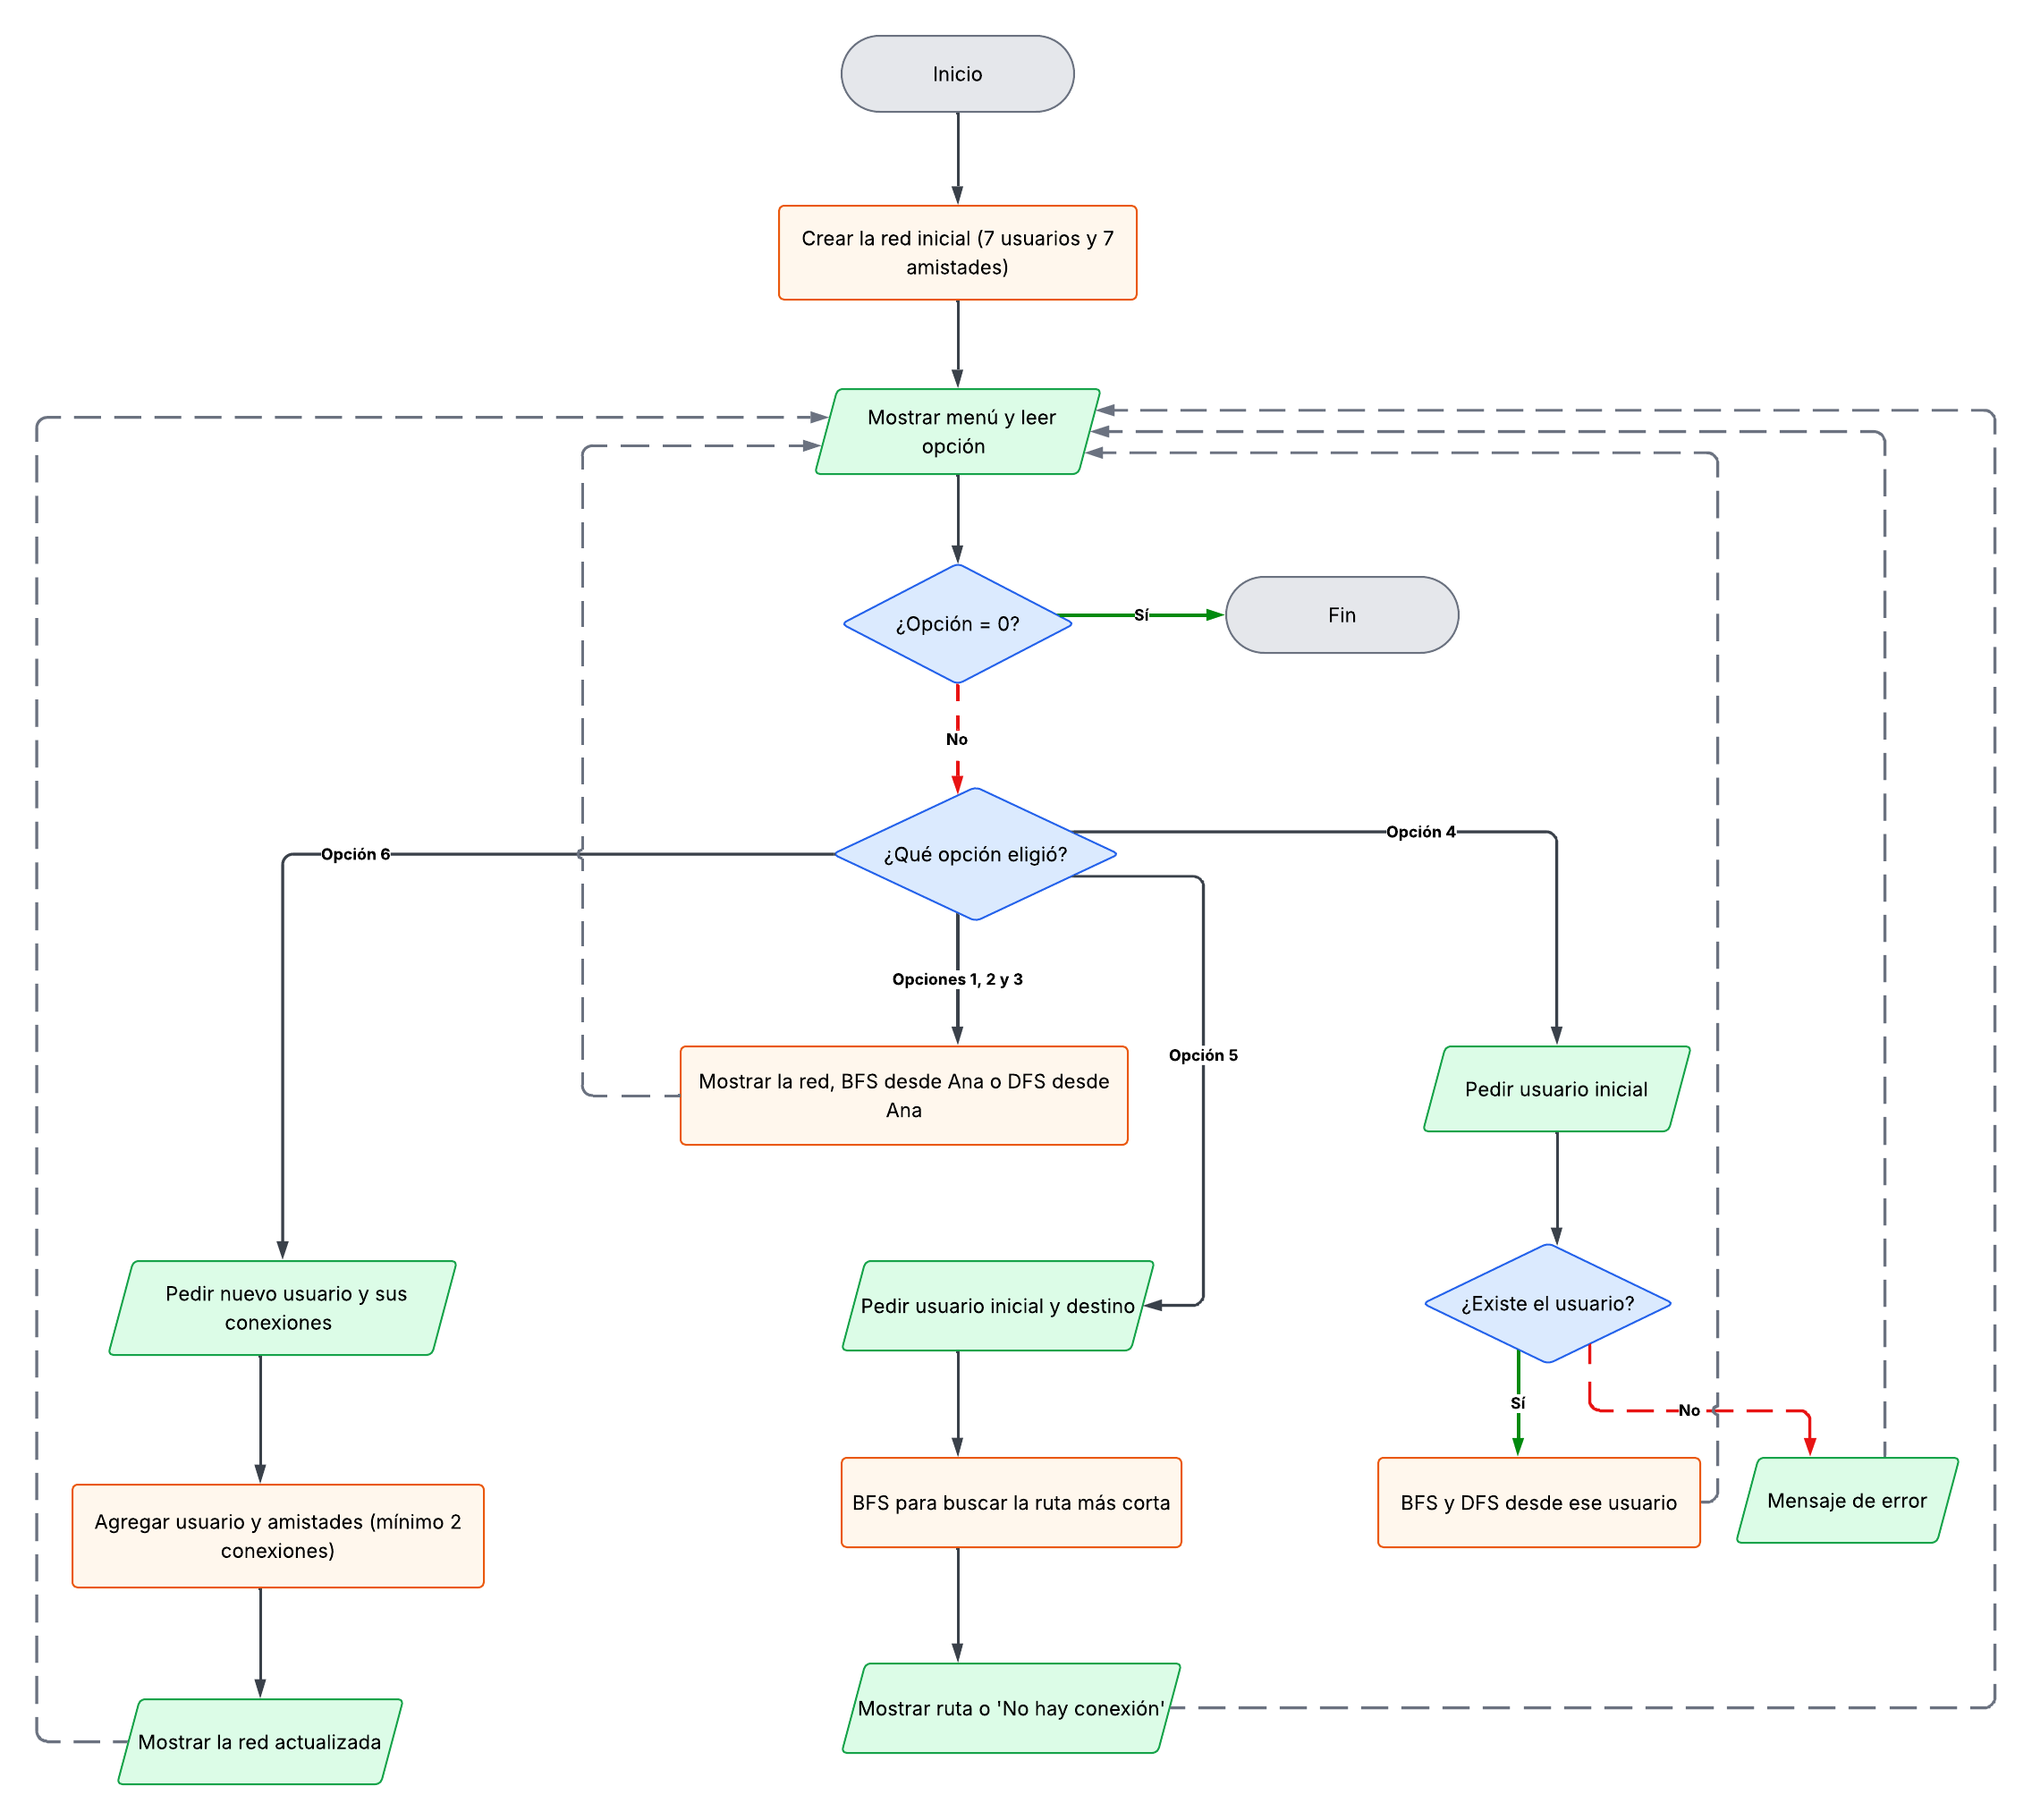


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

**Justificación**

V es el número de usuarios y E el número de amistades. En BFS cada usuario entra a la cola una sola vez porque lo marcamos como visitado apenas lo metemos. Cuando sale de la cola se revisan todos sus vecinos. Como cada amistad se guarda en los dos sentidos, entre todos los usuarios se revisan 2E vecinos. DFS hace lo mismo pero con recursividad, entonces tiene la misma complejidad.

**Función T[n]**

Para contar tomamos como 1 operación: meter un usuario a la cola, sacarlo y revisar un vecino. Si R es la cantidad de usuarios que se alcanzan desde el origen:

T(V, E) = R + R + (suma de los grados de los usuarios alcanzados) = 2R + suma de grados

Si se alcanzan todos (R = V) la suma de los grados es 2E, entonces:

T(V, E) = 2V + 2E, que es O(V + E)

Con la red inicial V = 7 y E = 7, entonces T = 2(7) + 2(7) = 28 operaciones.

**Mejor y peor caso**

- Mejor caso: el usuario inicial no tiene amigos. Solo se alcanza él mismo, entonces T = 2, que es O(1).
- Peor caso: un grafo completo (todos amigos de todos). Ahí E = V(V-1)/2 y T = V² + V, que es O(V²).
- Caso intermedio: una cadena de usuarios donde cada uno es amigo del siguiente (E = V - 1). Ahí T = 4V - 2, que es O(V).

En la siguiente celda se cuentan las operaciones con un BFS que tiene un contador y se comparan con estas fórmulas.


In [ ]:

def contarPasosBFS(p_red, p_inicio):
    pasos = 0
    visitados = {}
    cola = [p_inicio]
    pos = 0
    visitados[p_inicio] = 1
    pasos = pasos + 1
    while pos < len(cola):
        actual = cola[pos]
        pos = pos + 1
        pasos = pasos + 1
        for vecino in p_red[actual]:
            pasos = pasos + 1
            if vecino not in visitados:
                visitados[vecino] = 1
                cola.append(vecino)
                pasos = pasos + 1
    return pasos

def grafoCompleto(p_n):
    red = {}
    for i in range(p_n):
        red[i] = []
        for j in range(p_n):
            if i != j:
                red[i].append(j)
    return red


def grafoCadena(p_n):
    red = {}
    for i in range(p_n):
        red[i] = []
        if i > 0:
            red[i].append(i - 1)
        if i < p_n - 1:
            red[i].append(i + 1)
    return red


def grafoMejorCaso(p_n):
    red = {}
    red[0] = []
    for i in range(1, p_n):
        red[i] = []
        for j in range(1, p_n):
            if i != j:
                red[i].append(j)
    return red


redInicial = {0: [1, 2], 1: [0, 3, 4], 2: [0, 5], 3: [1], 4: [1, 6], 5: [2, 6], 6: [4, 5]}
assert contarPasosBFS(redInicial, 0) == 2 * 7 + 2 * 7
print("Red inicial: T =", contarPasosBFS(redInicial, 0), "operaciones")

print()
print("  V   mejor   cadena   peor")
for n in range(10, 101, 10):
    mejor = contarPasosBFS(grafoMejorCaso(n), 0)
    cadena = contarPasosBFS(grafoCadena(n), 0)
    peor = contarPasosBFS(grafoCompleto(n), 0)
    assert mejor == 2
    assert cadena == 4 * n - 2
    assert peor == n * n + n
    print(n, "   ", mejor, "   ", cadena, "   ", peor)
print()
print("Los resultados coinciden con las fórmulas.")


Red inicial: T = 28 operaciones

  V   mejor   cadena   peor
10     2     38     110
20     2     78     420
30     2     118     930
40     2     158     1640
50     2     198     2550
60     2     238     3660
70     2     278     4970
80     2     318     6480
90     2     358     8190
100     2     398     10100

Los resultados coinciden con las fórmulas.


**Gráfica del mejor y peor caso**

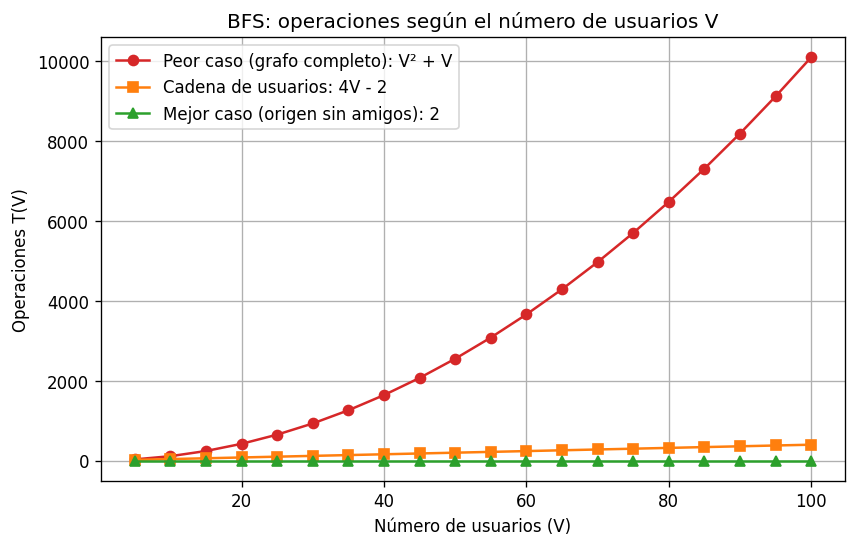

En la gráfica se ve que el mejor caso es una línea plana (siempre 2 operaciones), la cadena crece en línea recta y el grafo completo crece como una parábola (V²). Los datos salen de la tabla de la celda anterior.

En una red social de verdad casi nadie es amigo de todos, entonces E es mucho menor que V² y el recorrido se acerca más a O(V + E). Por eso conviene usar lista de adyacencia: solo se revisan las amistades que existen.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:

def agregarUsuario(p_red, p_nombre):
    if p_nombre in p_red:
        print("El usuario " + p_nombre + " ya existe")
    else:
        p_red[p_nombre] = []

def agregarAmistad(p_red, p_a, p_b):
    if p_a in p_red and p_b in p_red and p_a != p_b:
        if p_b not in p_red[p_a]:
            p_red[p_a].append(p_b)
            p_red[p_b].append(p_a)

def crearRedInicial():
    red = {}
    agregarUsuario(red, "Ana")
    agregarUsuario(red, "Carlos")
    agregarUsuario(red, "Laura")
    agregarUsuario(red, "Mateo")
    agregarUsuario(red, "Sofía")
    agregarUsuario(red, "Daniel")
    agregarUsuario(red, "Valentina")
    agregarAmistad(red, "Ana", "Carlos")
    agregarAmistad(red, "Ana", "Laura")
    agregarAmistad(red, "Carlos", "Mateo")
    agregarAmistad(red, "Carlos", "Sofía")
    agregarAmistad(red, "Laura", "Daniel")
    agregarAmistad(red, "Sofía", "Valentina")
    agregarAmistad(red, "Daniel", "Valentina")
    return red

def mostrarRed(p_red):
    for usuario in p_red:
        print(usuario + ": " + ", ".join(p_red[usuario]))


def bfs(p_red, p_inicio):
    visitados = {}
    grados = {}
    padres = {}
    cola = [p_inicio]   
    pos = 0
    visitados[p_inicio] = 1
    grados[p_inicio] = 0
    padres[p_inicio] = ""
    while pos < len(cola):
        actual = cola[pos]
        pos = pos + 1
        for vecino in p_red[actual]:
            if vecino not in visitados:
                visitados[vecino] = 1
                grados[vecino] = grados[actual] + 1
                padres[vecino] = actual
                cola.append(vecino)
    return cola, grados, padres

def mostrarBFS(p_red, p_inicio):
    if p_inicio not in p_red:
        print("Error: el usuario " + p_inicio + " no existe")
    else:
        orden, grados, padres = bfs(p_red, p_inicio)
        print("Recorrido BFS desde " + p_inicio + ": " + " -> ".join(orden))
        maximo = 0
        for usuario in orden:
            if grados[usuario] > maximo:
                maximo = grados[usuario]
        for g in range(maximo + 1):
            grupo = []
            for usuario in orden:
                if grados[usuario] == g:
                    grupo.append(usuario)
            print("Grado " + str(g) + ": " + ", ".join(grupo))



def dfsRec(p_red, p_actual, p_visitados, p_orden):
    p_visitados[p_actual] = 1
    p_orden.append(p_actual)
    for vecino in p_red[p_actual]:
        if vecino not in p_visitados:
            dfsRec(p_red, vecino, p_visitados, p_orden)

def dfs(p_red, p_inicio):
    visitados = {}
    orden = []
    dfsRec(p_red, p_inicio, visitados, orden)
    return orden

def mostrarDFS(p_red, p_inicio):
    if p_inicio not in p_red:
        print("Error: el usuario " + p_inicio + " no existe")
    else:
        orden = dfs(p_red, p_inicio)
        print("Recorrido DFS desde " + p_inicio + ": " + " -> ".join(orden))



def recorridosDesde(p_red, p_inicio):
    if p_inicio not in p_red:
        print("Error: el usuario " + p_inicio + " no existe")
    else:
        mostrarBFS(p_red, p_inicio)
        mostrarDFS(p_red, p_inicio)

def puntoCuatro(p_red):
    inicio = input("Ingrese el usuario inicial: ")
    recorridosDesde(p_red, inicio)



def rutaMasCorta(p_red, p_inicio, p_destino):
    # BFS
    orden, grados, padres = bfs(p_red, p_inicio)
    ruta = []
    if p_destino in grados:
        actual = p_destino
        while actual != "":
            ruta.insert(0, actual)
            actual = padres[actual]
    return ruta

def mostrarRuta(p_red, p_inicio, p_destino):
    if p_inicio not in p_red:
        print("Error: el usuario " + p_inicio + " no existe")
    if p_destino not in p_red:
        print("Error: el usuario " + p_destino + " no existe")
    if p_inicio in p_red and p_destino in p_red:
        ruta = rutaMasCorta(p_red, p_inicio, p_destino)
        if len(ruta) == 0:
            print("No hay conexión entre " + p_inicio + " y " + p_destino)
        else:
            print("Ruta encontrada:")
            print(" -> ".join(ruta))
            print("Grados de separación: " + str(len(ruta) - 1))

def puntoCinco(p_red):
    inicio = input("Usuario inicial: ")
    destino = input("Usuario destino: ")
    mostrarRuta(p_red, inicio, destino)


def registrarUsuario(p_red, p_nuevo, p_conexiones):
    valido = 1
    if p_nuevo == "":
        print("Error: el nombre no puede estar vacío")
        valido = 0
    if p_nuevo in p_red:
        print("Error: el usuario " + p_nuevo + " ya existe")
        valido = 0
    if len(p_conexiones) < 2:
        print("Error: hay que conectarlo con mínimo dos usuarios")
        valido = 0
    for i in range(len(p_conexiones)):
        if p_conexiones[i] not in p_red:
            print("Error: el usuario " + p_conexiones[i] + " no existe")
            valido = 0
        for j in range(i + 1, len(p_conexiones)):
            if p_conexiones[i] == p_conexiones[j]:
                print("Error: " + p_conexiones[i] + " está repetido")
                valido = 0
    if valido == 1:
        agregarUsuario(p_red, p_nuevo)
        for amigo in p_conexiones:
            agregarAmistad(p_red, p_nuevo, amigo)
        print("Usuario " + p_nuevo + " agregado con " + str(len(p_conexiones)) + " conexiones")
    return valido

def puntoSeis(p_red):
    nuevo = input("Nuevo usuario: ")
    conexiones = []
    otro = input("Conectar con (Enter para terminar): ")
    while otro != "":
        conexiones.append(otro)
        otro = input("Conectar con (Enter para terminar): ")
    if registrarUsuario(p_red, nuevo, conexiones) == 1:
        print("Red actualizada:")
        mostrarRed(p_red)



def demostracion():
    red = crearRedInicial()
    print("--- Punto 1: la red ---")
    mostrarRed(red)
    print()
    print("--- Punto 2: BFS desde Ana ---")
    mostrarBFS(red, "Ana")
    print()
    print("--- Punto 3: DFS desde Ana ---")
    mostrarDFS(red, "Ana")
    print()
    print("--- Punto 4: recorridos desde Sofía y desde un usuario que no existe ---")
    recorridosDesde(red, "Sofía")
    recorridosDesde(red, "Zoe")
    print()
    print("--- Punto 5: ruta de Ana a Valentina ---")
    mostrarRuta(red, "Ana", "Valentina")
    print()
    print("--- Punto 6: usuario nuevo Juliana conectada con Mateo y Daniel ---")
    registrarUsuario(red, "Juliana", ["Mateo", "Daniel"])
    mostrarRed(red)
    print()
    mostrarBFS(red, "Ana")
    mostrarDFS(red, "Ana")
    mostrarRuta(red, "Ana", "Juliana")


def mostrarMenu():
    print()
    print("========== RED SOCIAL ==========")
    print("1. Mostrar la red")
    print("2. BFS desde Ana")
    print("3. DFS desde Ana")
    print("4. BFS y DFS desde un usuario")
    print("5. Ruta más corta entre dos usuarios")
    print("6. Agregar un usuario nuevo")
    print("7. Demostración de todos los puntos")
    print("0. Salir")

def main():
    red = crearRedInicial()
    opcion = ""
    while opcion != "0":
        mostrarMenu()
        opcion = input("Opción: ")
        if opcion == "1":
            mostrarRed(red)
        if opcion == "2":
            mostrarBFS(red, "Ana")
        if opcion == "3":
            mostrarDFS(red, "Ana")
        if opcion == "4":
            puntoCuatro(red)
        if opcion == "5":
            puntoCinco(red)
        if opcion == "6":
            puntoSeis(red)
        if opcion == "7":
            demostracion()
        if opcion not in ["0", "1", "2", "3", "4", "5", "6", "7"]:
            print("Opción no válida")
    print("Programa terminado")

if __name__ == "__main__":
    main()



========== RED SOCIAL ==========
1. Mostrar la red
2. BFS desde Ana
3. DFS desde Ana
4. BFS y DFS desde un usuario
5. Ruta más corta entre dos usuarios
6. Agregar un usuario nuevo
7. Demostración de todos los puntos
0. Salir
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofía
Laura: Ana, Daniel
Mateo: Carlos
Sofía: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofía, Daniel

========== RED SOCIAL ==========
1. Mostrar la red
2. BFS desde Ana
3. DFS desde Ana
4. BFS y DFS desde un usuario
5. Ruta más corta entre dos usuarios
6. Agregar un usuario nuevo
7. Demostración de todos los puntos
0. Salir
Usuario Ramon agregado con 2 conexiones
Red actualizada:
Ana: Carlos, Laura, Ramon
Carlos: Ana, Mateo, Sofía, Ramon
Laura: Ana, Daniel
Mateo: Carlos
Sofía: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofía, Daniel
Ramon: Ana, Carlos

========== RED SOCIAL ==========
1. Mostrar la red
2. BFS desde Ana
3. DFS desde Ana
4. BFS y DFS desde un usuario
5. Ruta más corta entre dos usuarios

## 7) Tests aplicados **[15 pts]**

In [ ]:

red = crearRedInicial()
assert len(red) == 7
assert red["Ana"] == ["Carlos", "Laura"]
assert red["Carlos"] == ["Ana", "Mateo", "Sofía"]
assert red["Valentina"] == ["Sofía", "Daniel"]
print("Test 1 ok: lista de adyacencia")


orden, grados, padres = bfs(red, "Ana")
assert orden == ["Ana", "Carlos", "Laura", "Mateo", "Sofía", "Daniel", "Valentina"]
assert grados["Ana"] == 0
assert grados["Carlos"] == 1
assert grados["Daniel"] == 2
assert grados["Valentina"] == 3
print("Test 2 ok: BFS desde Ana")

assert dfs(red, "Ana") == ["Ana", "Carlos", "Mateo", "Sofía", "Valentina", "Daniel", "Laura"]
print("Test 3 ok: DFS desde Ana")


orden, grados, padres = bfs(red, "Sofía")
assert orden == ["Sofía", "Carlos", "Valentina", "Ana", "Mateo", "Daniel", "Laura"]
assert dfs(red, "Sofía") == ["Sofía", "Carlos", "Ana", "Laura", "Daniel", "Valentina", "Mateo"]
assert len(orden) == 7
assert "Zoe" not in red
print("Test 4 ok: recorridos desde Sofía y usuario que no existe")

# Test 5: ruta más corta
assert rutaMasCorta(red, "Ana", "Valentina") == ["Ana", "Carlos", "Sofía", "Valentina"]
assert len(rutaMasCorta(red, "Ana", "Valentina")) - 1 == 3
assert rutaMasCorta(red, "Mateo", "Mateo") == ["Mateo"]
print("Test 5 ok: ruta más corta")


agregarUsuario(red, "Pedro")
assert rutaMasCorta(red, "Ana", "Pedro") == []
print("Test 6 ok: sin conexión")

red = crearRedInicial()
agregarAmistad(red, "Ana", "Carlos")
agregarAmistad(red, "Carlos", "Ana")
agregarAmistad(red, "Ana", "Zoe")
assert red["Ana"] == ["Carlos", "Laura"]
assert "Mateo" in red["Carlos"]
assert "Carlos" in red["Mateo"]
print("Test 7 ok: sin amistades repetidas y en los dos sentidos")

assert registrarUsuario(red, "Juliana", ["Mateo"]) == 0
assert registrarUsuario(red, "Juliana", ["Mateo", "Zoe"]) == 0
assert registrarUsuario(red, "Juliana", ["Mateo", "Mateo"]) == 0
assert registrarUsuario(red, "Ana", ["Mateo", "Daniel"]) == 0
assert len(red) == 7
assert registrarUsuario(red, "Juliana", ["Mateo", "Daniel"]) == 1
assert len(red) == 8
assert red["Juliana"] == ["Mateo", "Daniel"]
assert rutaMasCorta(red, "Ana", "Juliana") == ["Ana", "Carlos", "Mateo", "Juliana"]
assert len(dfs(red, "Ana")) == 8
print("Test 8 ok: usuario nuevo")

print()
print("Todos los tests pasaron")
